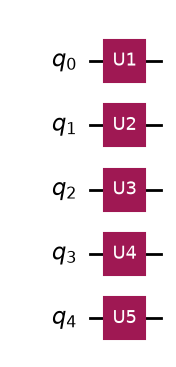

In [54]:
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import random_unitary
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

num_qubits=5
random_ugate=random_unitary(2)

qc=QuantumCircuit(num_qubits)
qc.unitary(random_ugate, [0], label = "U1")
qc.unitary(random_ugate, [1], label = "U2")
qc.unitary(random_ugate, [2], label = "U3")
qc.unitary(random_ugate, [3], label = "U4")
qc.unitary(random_ugate, [4], label = "U5")

qc.draw(output='mpl')

In [55]:
#%pip install pylatexenc

In [59]:
# now we calculate, say for example, the expectation value of the Z operator on the first qubit, after applying the random unitary.
#we will then plot the epectation value of Z as a function of the cirucit depth

observable = SparsePauliOp("IIIIZ")

# --- 3. Run the estimator directly on the circuit ---
estimator = StatevectorEstimator()

# Define the PUB (Primitive Unified Bloc) as a tuple of (circuit, observable)
pub = (qc, observable)
job = estimator.run([pub])
result = job.result()

# --- 4. Get your expectation value ---
# evs contains an array of results; get the first element
exp_val_q0 = result[0].data.evs 

print(f"Expectation value of Z on Qubit 0: {exp_val_q0}")

Expectation value of Z on Qubit 0: 0.2542741024356837
